为了体现 mqchem 模块在处理复杂量子化学算法时的通用性与高效性，我们基于 mqchem 模块实现三种改进版本的 VQE 算法：**Sym-UCCSD**、 **$k$-UpCCGSD** 和 **ADAPT-VQE**。

## A. Sym-UCCSD 

针对 UCCSD 拟设存在量子线路深度过大的问题，Sym-UCCSD (symmetry-reduced unitary coupled-cluster singles and doubles) 方法 [1] 以**分子点群对称性**为核心约束，通过**筛除不满足分子点群对称性要求的激发算符**，构建出更精简的拟设形式。 该方法的具体实现流程如下：

   - 基于分子的几何结构，确定其所属的**点群**；
   - 推导各分子轨道对应的**不可约表示**，并构建相应的不可约表示乘积表；
   - 根据涉及的分子轨道，明确**参考态的不可约表示**； 
   - 计算各激发算符作用后生成的**激发态的不可约表示**；
   - 滤除拟设中所有对应激发态不可约表示与参考态不可约表示不同的激发算符。

这里，我们基于 **pyscf** 开发包自动化实现上述步骤，并使用 mqchem 模块执行构造出的拟设，计算氟化氢（HF）分子的基态能。

为简洁起见，我们将部分代码封装成了函数。完整代码已托管到 MindSpore Quantum 仓库，感兴趣的读者可以点击此[链接](https:)获取。


In [1]:
from tools import *
from algorithms import *
from mindquantum import *

# 我们将相关函数存在了 tools.py 和 algorithms.py 文件

geo = [['H', [0,0,0]], ['F', [0,0,1]]] # 氟化氢分子，键长为 1 埃
hf, fci, ham, n_qubits, n_electrons = get_mole_info(geo) # 基于 pyscf 计算分子的 HF FCI 能量，并获取哈密顿量等信息

print("关联能为")
print(abs(hf-fci))

sim = mqchem.MQChemSimulator(n_qubits, n_electrons)

uccsd = get_uccsd(n_qubits, n_electrons)
sym_uccsd = sym_filter(geo, uccsd, n_electrons)

print(f"\nuccsd, sym-uccsd 的参数量分别为")
print(len(sum(uccsd).params_name), len(sum(sym_uccsd).params_name))

print(f"\nuccsd, sym-uccsd 的激发算符数分别为")
print(len(uccsd), len(sym_uccsd))

uccsd_res, _ = run_vqe(ham, n_qubits, n_electrons, get_circ(uccsd))
sym_uccsd_res, _ = run_vqe(ham, n_qubits, n_electrons, get_circ(sym_uccsd))

print("\nuccsd, sym-uccsd 的计算误差分别为")
print(abs(fci-uccsd_res), abs(fci-sym_uccsd_res))

关联能为
0.0327848154016408

点群名称为
 Coov

uccsd, sym-uccsd 的参数量分别为
20 11

uccsd, sym-uccsd 的激发算符数分别为
35 17

uccsd, sym-uccsd 的计算误差分别为
8.820830288414072e-07 8.820830146305525e-07


## B. $k$-UpCCGSD 

传统 UCCSD 拟设的激发算符数量随分子轨道数 $N$ 呈 $O(N^4)$ 规模增长，即便采用最大并行执行策略，其量子线路深度仍维持在 $O(N^3)$ 级别，这一高复杂度限制了其在中大分子体系中的实际应用。为突破这一瓶颈，Joonho Lee 等人提出了 $k$-UpCCGSD ($k$-Unitary Pair Coupled-Cluster with Generalized Singles and Doubles) 拟设方案 [2]，实现了拟设复杂度的显著降低。

$k$-UpCCGSD 拟设的核心激发算符集合包含两类关键成分：

    - 所有广义单激发算符（generalized single excitation operators）；
    - 所有 “成对的” 广义双激发算符（paired generalized double excitation operators）。

其中，“广义”指的激发算符的作用范围不受限于传统 UCCSD 中**占据轨道到虚拟轨道**（occupied $\rightarrow$ virtual）的跃迁模式，而是进一步涵盖**占据轨道间**（occupied $\rightarrow$ occupied），以及**虚拟轨道间**（virtual $\rightarrow$ virtual）的跃迁过程，从而更全面地捕捉电子关联效应；“成对的” 双激发算符则是将跃迁过程约束于两个分子轨道对之间，从而降低双激发算符的数量。为进一步提升能量计算精度，可将上述基础拟设单元重复堆叠 $k$ 次，且每次堆叠所对应的参数相互独立，形成 $k$ 层拟设结构。

$k$-UpCCGSD 拟设的激发算符数量仅随 $N$呈 $O(N^2)$ 增长，结合并行执行策略后，量子线路深度可优化至 $O(kN)$，也即实现了**线性级别的线路深度**。

为直观展示 $k$-UpCCGSD 拟设的构造逻辑，本节以氟化氢分子基态能量求解作为案例，并基于 mqchem 模块完成拟设的仿真计算。

In [2]:
geo = [['H', [0,0,0]], ['F', [0,0,1]]] # 氟化氢分子，键长为 1 埃
hf, fci, ham, n_qubits, n_electrons = get_mole_info(geo)

k = 2
ansatz = get_k_upccgsd(n_qubits, k) # 构建 k_upccgsd 拟设
res, _ = run_vqe(ham, n_qubits, n_electrons, get_circ(ansatz))

print(f"{k}-UpCCGSD 拟设中激发算符数为")
print(len(ansatz))

print(f"\n{k}-UpCCGSD 的计算误差为")
print(abs(fci-res))


2-UpCCGSD 拟设中激发算符数为
90

2-UpCCGSD 的计算误差为
2.842170943040401e-14


## C. ADAPT-VQE

与前述 Sym-UCCSD、$k$-UpCCGSD 两类固定结构的量子拟设不同，ADAPT-VQE（Adaptive Derivative-Assembled Pseudo-Trotter ansatz Variational Quantum Eigensolver） 算法 [3] 采用**动态构建拟设**的核心思路：首先将 UCCSD 拟设包含的所有激发算符整合为一个完备的“**激发算符池**”，通过迭代优化机制逐步筛选关键激发算符，最终形成适配目标分子体系的精简拟设。

其具体迭代流程如下：
1. 初始化空拟设与参考态，设定梯度阈值等终止条件；
2. 在每次迭代中，计算激发算符池中所有激发算符在当前拟设态、参数为 0 时的**能量梯度**；
3. 选取**梯度绝对值最大的激发算符**（即对能量降低贡献最显著的算符）加入拟设；
4. 优化当前拟设的所有参数直至收敛，随后进入下一轮迭代；
5. 若某轮迭代中，算符池内所有剩余激发算符的梯度向量范数小于预设阈值，则终止迭代。

ADAPT-VQE 具备显著的方法优势：首先，该方法可以自动挑选出最关键的激发算符构造紧凑的拟设，**线路深度浅**；其次，通过调整梯度阈值等终止条件，原则上可逼近**任意精度**要求；最后，采用“**暖启动**”优化策略，新增激发算符后直接复用前序迭代的最优参数，不仅提升了收敛效率，还能有效缓解量子优化中常见的局部最优问题与贫瘠高原现象。

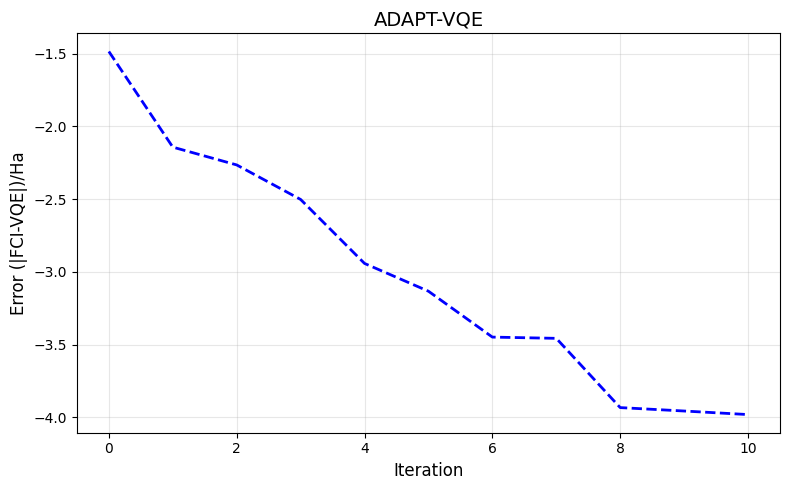

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

geo = [['H', [0,0,0]], ['F', [0,0,1]]] # 氟化氢分子，键长为 1 埃

tol = 1e-2 # 终止迭代阈值
energys, errors = run_adapt_vqe(geo, tol)

plt.figure(figsize=(8, 5))
plt.plot(range(len(errors)), np.log10(errors), color='blue', linestyle='--', linewidth=2, label='errors')
plt.title('ADAPT-VQE', fontsize=14)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Error (|FCI-VQE|)/Ha', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

[1] Cao C, Hu J, Zhang W, et al. Progress toward larger molecular simulation on a quantum computer: Simulating a system with up to 28 qubits accelerated by point-group symmetry[J]. Physical Review A, 2022, 105(6): 062452.

[2] Lee J, Huggins W J, Head-Gordon M, et al. Generalized unitary coupled cluster wave functions for quantum computation[J]. Journal of chemical theory and computation, 2018, 15(1): 311-324.

[3] Grimsley H R, Economou S E, Barnes E, et al. An adaptive variational algorithm for exact molecular simulations on a quantum computer[J]. Nature communications, 2019, 10(1): 3007.